# 06 — End-to-end ultrasound demo

One image, the whole workflow, exactly as the app runs it at inference time:

YOLO26n box → U-Net mask → native-resolution mask + QC → PyRadiomics → validated JSON record →
radiomics classifier (if a compatible artifact exists) → reference retrieval → grounded report.

Every component is optional. If a checkpoint, dependency, model artifact, index or LLM is missing,
the cell says what is unavailable and the rest still runs. No dataset label is used anywhere.

Set `REPORT_BACKEND` to `"local"` to use the cached Qwen model instead of the offline stub.

> Research model output — not a clinical diagnosis.

## Setup and component check

In [1]:
import json
import os
import sys
from pathlib import Path

# Resolve the repo root whether the kernel starts in notebooks/ or at the root:
# config.yaml paths (dataset/, checkpoints/, results/) are relative to it.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "config.yaml").exists() and (p / "bus_research").is_dir())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.config import load_config
from utils.seed import get_device, set_seed

config = load_config(str(REPO_ROOT / "config.yaml"))
set_seed(config["seed"], config["deterministic"])
RESEARCH = config["research"]
print(f"Repo root: {REPO_ROOT}")

Repo root: /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection


In [2]:
import bus_research
from bus_research.classifier import load_if_present

IMAGE_PATH = None          # None = first image of the held-out test split; or any ultrasound file path
REPORT_BACKEND = os.environ.get("BUS_REPORT_BACKEND", RESEARCH["reports"]["llm_backend"])

inf = config["inference"]
status = {
    "checkpoints": all(Path(inf[k]).exists() for k in ("yolo_weights", "unet_weights", "resnet_weights")),
    "research deps": not bus_research.missing_dependencies(),
    "classifier artifact": (REPO_ROOT / RESEARCH["models"]["classifier_dir"] / "model.joblib").exists(),
    "RAG index": (REPO_ROOT / RESEARCH["rag"]["index_dir"] / "index_manifest.json").exists(),
}
for k, v in status.items():
    print(f"{k:20s} {'available' if v else 'UNAVAILABLE'}")
print(f"{'report backend':20s} {REPORT_BACKEND}")
print(f"{'BI-RADS model':20s} UNAVAILABLE (no validated BI-RADS labels; see notebook 01)")
if not status["research deps"]:
    print("missing packages:", bus_research.missing_dependencies(), "-> pip install -r requirements-research.txt")

checkpoints          available
research deps        available
classifier artifact  available
RAG index            available
report backend       stub
BI-RADS model        UNAVAILABLE (no validated BI-RADS labels; see notebook 01)


## 1. Detection and segmentation (existing pipeline)

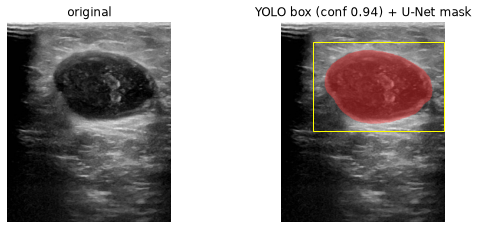

ResNet50 (existing Stage 4, uncalibrated): {'benign': 0.757, 'malignant': 0.243}


In [3]:
import matplotlib.pyplot as plt
import numpy as np

from dataset.splits import load_split
from preprocessing.normalization import load_image_rgb

if IMAGE_PATH is None:
    IMAGE_PATH = load_split(config["paths"]["splits_dir"], "test")[0]["image_path"]
image = load_image_rgb(IMAGE_PATH)
case = None
if status["checkpoints"]:
    from inference.pipeline import build_pipeline
    pipeline = build_pipeline(config)
    try:
        case = pipeline.run(IMAGE_PATH)
    except RuntimeError as exc:
        print("No lesion detected:", exc, "-> in the app the clinician draws the box manually.")
else:
    print("Checkpoints unavailable: the cascade cannot run (train them with `python train.py all`).")

if case is not None:
    from bus_research.radiomics_extract import native_mask_from_roi
    native = native_mask_from_roi(case.mask, case.bbox, image.shape)
    overlay = image.copy()
    overlay[native > 0] = (0.55 * overlay[native > 0] + 0.45 * np.array([255, 60, 60])).astype(np.uint8)
    x1, y1, x2, y2 = case.bbox
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), dpi=72)
    axes[0].imshow(image); axes[0].set_title("original")
    axes[1].imshow(overlay); axes[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow"))
    axes[1].set_title(f"YOLO box (conf {case.detection_confidence:.2f}) + U-Net mask")
    for a in axes:
        a.axis("off")
    plt.show()
    print("ResNet50 (existing Stage 4, uncalibrated):", {k: round(v, 3) for k, v in case.class_probs.items()})

## 2. Radiomics → validated JSON record (inference-time, label-free)

In [4]:
record = None
if case is not None and status["research deps"]:
    from bus_research import birads
    from bus_research.feature_store import build_record, image_content_id, save_record
    from bus_research.radiomics_extract import (UNET_ACTIVATION, UNET_THRESHOLD, RadiomicsSettings,
                                                extract_radiomics_features)

    settings = RadiomicsSettings.from_config(config)
    result = extract_radiomics_features(image, native, {"roi_bbox": list(case.bbox)}, settings)
    print("extraction:", result["status"], "| mask QC:", result["qc"]["status"],
          [i["message"] for i in result["qc"]["issues"]] or "")
    record = build_record(
        image_key=image_content_id(image), lesion_key="top_detection", image=image, radiomics_result=result,
        segmentation={"model": "unet", "checkpoint_version": None, "mask_source": "predicted",
                      "activation": UNET_ACTIVATION, "threshold": UNET_THRESHOLD, "bbox_source": "yolo",
                      "detection_confidence": case.detection_confidence, "roi_bbox_xyxy": list(case.bbox)},
        descriptors=birads.empty_descriptors(),
        limitations=["Shape features in pixel units (no physical calibration)."],
        provenance={"pipeline": "notebook 06 demo"})
    if result["status"] == "ok":
        f = result["features"]
        print({"area_px2": f["shape2D"]["PixelSurface"], "elongation": round(f["shape2D"]["Elongation"], 3),
               "sphericity": round(f["shape2D"]["Sphericity"], 3), "mean_gray": round(f["firstorder"]["Mean"], 1),
               "glcm_contrast": round(f["glcm"]["Contrast"], 3)})

extraction: ok | mask QC: pass 


{'area_px2': 56114.0, 'elongation': 0.678, 'sphericity': 0.863, 'mean_gray': 48.6, 'glcm_contrast': 0.528}


## 3. Classifier (only if a compatible trained artifact exists)

In [5]:
prediction = {"available": False, "reason": "classifier artifact not available"}
if record is not None and status["classifier artifact"]:
    clf = load_if_present(REPO_ROOT / RESEARCH["models"]["classifier_dir"])
    prediction = clf.predict(record)
if prediction.get("available"):
    record["prediction"] = {k: prediction[k] for k in ("model_id", "prediction_type", "class_probabilities",
                                                        "calibration_status", "calibration_method")}
    print(f"{prediction['model_id']}: p(malignant) = {prediction['class_probabilities']['malignant']:.3f} "
          f"| calibration: {prediction['calibration_status']} | OOD: {prediction['ood']['out_of_distribution']}")
    print("Research model output — not a clinical diagnosis.")
else:
    print("Classifier output unavailable:", prediction["reason"])
print("BI-RADS assessment unavailable: validated BI-RADS labels/model not configured.")

if record is not None:
    from bus_research.feature_store import save_record
    path = save_record(REPO_ROOT / RESEARCH["radiomics"]["output_dir"] / "inference", record)
    print("saved", path.relative_to(REPO_ROOT))

radiomics-gradient-boosting-c622ae6f: p(malignant) = 0.396 | calibration: calibrated | OOD: False
Research model output — not a clinical diagnosis.
BI-RADS assessment unavailable: validated BI-RADS labels/model not configured.
saved results/radiomics/inference/records/rec_a7b42fcd2dc2.json


## 4. Evidence retrieval and the grounded report

In [6]:
from bus_research import report as rp
from bus_research.feature_store import atomic_write_json

if record is not None:
    hits = []
    index = None
    if status["RAG index"]:
        from bus_research import rag
        index = rag.ReferenceIndex.load(REPO_ROOT / RESEARCH["rag"]["index_dir"])
        query = rag.build_query(record, prediction)
        hits = list({h["chunk_id"]: h for h in index.search(query, k=2, tiers=("primary_reference",))
                     + index.search(query, k=RESEARCH["rag"]["top_k"])}.values())
    else:
        print("RAG index unavailable: run notebook 03. The report will have no reference evidence.")
    try:
        cfg = json.loads(json.dumps(config))
        cfg["research"]["reports"]["llm_backend"] = REPORT_BACKEND
        llm = rp.build_provider(cfg)
    except Exception as exc:  # noqa: BLE001
        llm = None
        print("LLM provider unavailable:", exc)
    report = rp.generate_report(record, prediction, hits, llm, index_version=index.version if index else None)
    out = REPO_ROOT / RESEARCH["reports"]["output_dir"]
    atomic_write_json(out / f"{record['record_id']}_demo.json", report)
    (out / f"{record['record_id']}_demo.md").write_text(rp.report_to_markdown(report))
    print(rp.report_to_markdown(report))

# Quantitative ultrasound research report — rec_a7b42fcd2dc2

> Research model output — not a clinical diagnosis.

- **Status:** ok
- **Requires radiologist review:** yes
- **BI-RADS:** BI-RADS assessment unavailable: validated BI-RADS labels/model not configured.
- **Classifier (benign_vs_malignant, radiomics-gradient-boosting-c622ae6f):** p(malignant) = 0.396 · calibration: calibrated
- **Provider:** stub / template-narrative-v1 · RAG index rag-c47fd3b06bdb · generated 2026-10-29T11:28:37.529616+00:00

## Summary

Quantitative analysis of the lesion outlined by the predicted mask (mask quality: pass). The outlined area is 56114.0 px^2 (pixel units; no physical calibration). The radiomics benign-vs-malignant research model gives p(malignant) = 0.396 (calibration status: calibrated). BI-RADS descriptors were not assessed and no BI-RADS assessment is available.

## BI-RADS descriptors

| Descriptor | Status | Value | Source |
|---|---|---|---|
| shape | Descriptor not assessed | — | not

## What this demo does **not** show

* No BI-RADS category: none can be produced validly from BUSI (notebooks 01 and 04).
* No BI-RADS descriptors: they are reported as *not assessed*. Radiomics numbers are not descriptors.
* No management recommendation: the report only says what a radiologist should review.